# Fine-tuning experiments (mục 14 đến 19, 21)

Mỗi cấu hình chạy trong một tiến trình riêng bằng pretrained_classification.py và ghi vào results.csv. Cấu hình đã có trong results.csv sẽ được bỏ qua. Dữ liệu và thời gian chạy ghi ở README.md.

In [1]:
import json, os, subprocess, sys, tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

RUNS_DIR = Path(os.environ.get("LAB08_RUNS", Path(tempfile.gettempdir()) / "lab08_runs"))
SEED = 42

def run(experiment, mode, seed, fraction=1.0, max_length=128, domain_b=False):
    cmd = [sys.executable, "pretrained_classification.py", "--experiment", experiment, "--mode", mode,
           "--seed", str(seed), "--fraction", str(fraction), "--max-length", str(max_length)]
    if domain_b:
        cmd.append("--domain-b")
    out = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace")
    print(out.stdout, flush=True)
    if out.returncode != 0:
        raise RuntimeError(out.stderr[-3000:])

## Chạy thí nghiệm

Mỗi cấu hình chạy 1 lần với seed 42.

In [2]:
# Exp 1, 2, 5: baseline fine-tuning (also tested on Amazon), from scratch, frozen
run("baseline", "finetune", SEED, domain_b=True)
run("exp1_scratch", "scratch", SEED)
run("exp2_frozen", "frozen", SEED)

finetune_f1_T128_s42: already in results.csv, skipped



scratch_f1_T128_s42: already in results.csv, skipped



frozen_f1_T128_s42: already in results.csv, skipped



In [3]:
# Exp 3: amount of training data. The 100% points are the runs above.
for fraction in [0.1, 0.25, 0.5]:
    run("exp3", "finetune", SEED, fraction=fraction)
    run("exp3", "scratch", SEED, fraction=fraction)

finetune_f0.1_T128_s42: already in results.csv, skipped



scratch_f0.1_T128_s42: already in results.csv, skipped



finetune_f0.25_T128_s42: already in results.csv, skipped



scratch_f0.25_T128_s42: already in results.csv, skipped



finetune_f0.5_T128_s42: already in results.csv, skipped



scratch_f0.5_T128_s42: already in results.csv, skipped



In [4]:
# Exp 4: maximum sequence length. T = 128 is the baseline.
for T in [64, 256]:
    run("exp4", "finetune", SEED, max_length=T)

finetune_f1_T64_s42: already in results.csv, skipped



finetune_f1_T256_s42: already in results.csv, skipped



## Kết quả

In [5]:
df = pd.read_csv("results.csv")
pd.set_option("display.width", 160)
METRICS = ["accuracy", "precision", "recall", "f1"]

def summary(frame, by):
    g = frame.groupby(by)
    out = g[METRICS + ["train_time_s"]].mean().round(4)
    return out

imdb = df[df.test_domain == "imdb"]
full = imdb[(imdb.train_fraction == 1.0) & (imdb.max_length == 128)]

### Experiment 1 và 2: from scratch, frozen, fine-tuning

In [6]:
t = summary(full, "mode")
t["n_params"] = full.groupby("mode")["n_params"].first()
t["n_trainable"] = full.groupby("mode")["n_trainable_params"].first()
t["best_epoch"] = full.groupby("mode")["best_epoch"].apply(list)
t

,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,best_epoch
mode,,,,,,,,
finetune,0.866,0.8720,0.858,0.8649,810.5,66364418,66364418,[2]
frozen,0.781,0.8486,0.684,0.7575,110.8,66364418,1538,[1]
scratch,0.690,0.6578,0.792,0.7187,265.9,4453634,4453634,[6]


### Experiment 3: lượng dữ liệu

In [7]:
frac = imdb[(imdb.max_length == 128) & imdb["mode"].isin(["finetune", "scratch"])]
summary(frac, ["mode", "train_fraction"])

accuracy  precision  recall      f1  train_time_s
mode     train_fraction                                                   
finetune 0.10               0.675     0.6437   0.784  0.7069         205.1
         0.25               0.812     0.8035   0.826  0.8146         389.7
         0.50               0.833     0.8310   0.836  0.8335         706.3
         1.00               0.866     0.8720   0.858  0.8649         810.5
scratch  0.10               0.566     0.5552   0.664  0.6047          65.5
         0.25               0.609     0.6764   0.418  0.5167         146.9
         0.50               0.663     0.6304   0.788  0.7004         270.0
         1.00               0.690     0.6578   0.792  0.7187         265.9

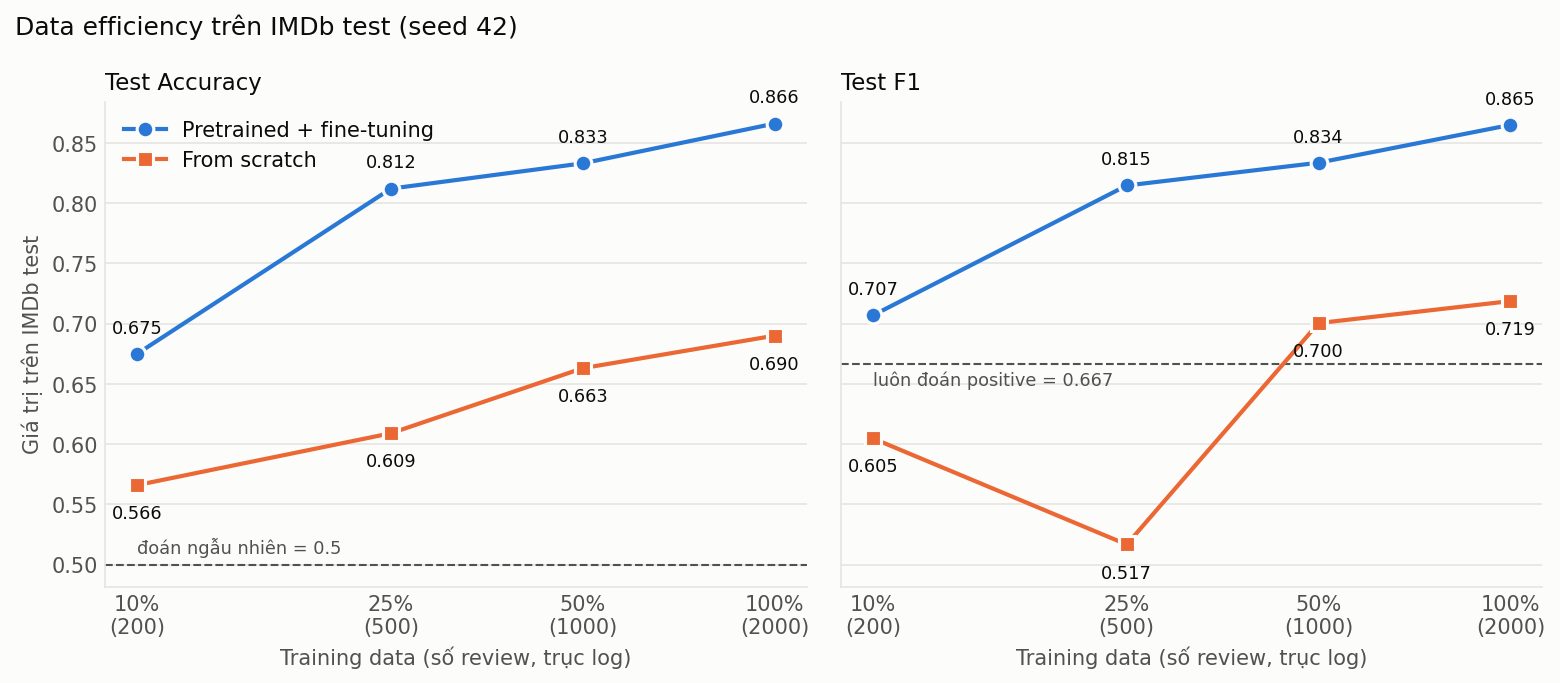

In [8]:
COLORS = {"finetune": "#2a78d6", "scratch": "#eb6834"}
LABELS = {"finetune": "Pretrained + fine-tuning", "scratch": "From scratch"}
MARKERS = {"finetune": "o", "scratch": "s"}
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"

def style(fig, ax):
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), dpi=150, sharey=True)
ticks = sorted(frac.train_size.unique())
panels = [("accuracy", "Accuracy", 0.5, "đoán ngẫu nhiên = 0.5", 1), ("f1", "F1", 2 / 3, "luôn đoán positive = 0.667", -1)]
for ax, (metric, name, ref, ref_label, side) in zip(axes, panels):
    ax.axhline(ref, color=MUTED, linewidth=1, linestyle="--")
    ax.text(ticks[0], ref + side * 0.006, ref_label, ha="left", va="bottom" if side > 0 else "top", color=MUTED, fontsize=8.5)
    for mode, offset in [("finetune", 10), ("scratch", -16)]:
        g = frac[frac["mode"] == mode].groupby("train_size")[metric]
        x, mean = g.mean().index.values, g.mean().values
        ax.plot(x, mean, color=COLORS[mode], linewidth=2, marker=MARKERS[mode], markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=LABELS[mode])
        for i in range(len(x)):
            ax.annotate(f"{mean[i]:.3f}", (x[i], mean[i]), xytext=(0, offset), textcoords="offset points",
                        ha="center", color=INK, fontsize=8.5)
    style(fig, ax)
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{f:.0%}\n({n})" for f, n in zip(sorted(frac.train_fraction.unique()), ticks)])
    ax.minorticks_off()
    ax.set_xlabel("Training data (số review, trục log)", color=MUTED)
    ax.set_title(f"Test {name}", loc="left", color=INK, fontsize=11)
axes[0].set_ylabel("Giá trị trên IMDb test", color=MUTED)
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK)
fig.suptitle("Data efficiency trên IMDb test (seed 42)", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig("data_efficiency.png")
plt.show()

### Experiment 4: sequence length (seed 42)

In [9]:
t4 = imdb[(imdb["mode"] == "finetune") & (imdb.train_fraction == 1.0) & (imdb.seed == 42)].sort_values("max_length")
t4[["max_length", "accuracy", "f1", "train_time_s", "peak_memory_mb"]]

,max_length,accuracy,f1,train_time_s,peak_memory_mb
10,64,0.799,0.8080,747.1,2197
0,128,0.866,0.8649,810.5,2980
11,256,0.892,0.8907,2852.2,4593


train_time_s ở bảng trên là thời gian thực của cả lần chạy, bị ảnh hưởng khi máy đang chạy việc khác. Cell dưới đo lại thời gian một bước train (forward, backward, optimizer step, batch 16) trong cùng một tiến trình, xen kẽ các giá trị T qua nhiều vòng để tải nền ảnh hưởng đều lên cả ba.

In [10]:
import time
import torch
import pretrained_classification as pc
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(pc.MODEL_NAME)
texts = pd.read_json(RUNS_DIR / "finetune_f1_T128_s42_imdb.jsonl", lines=True).text[:16].tolist()
torch.manual_seed(0)
model = pc.PretrainedClassifier()
model.train()
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
labels = torch.zeros(16, dtype=torch.long)
batches = {T: tok(texts, padding="max_length", truncation=True, max_length=T, return_tensors="pt") for T in [64, 128, 256]}

def step(b):
    opt.zero_grad()
    torch.nn.functional.cross_entropy(model(b["input_ids"], b["attention_mask"]), labels).backward()
    opt.step()

for b in batches.values():
    step(b)  # warm-up
times = {T: [] for T in batches}
for _ in range(5):
    for T, b in batches.items():
        t0 = time.perf_counter()
        step(b)
        times[T].append(time.perf_counter() - t0)

# Per layer: projections + feed-forward ~ 12*T*d^2, attention scores QK^T and AV ~ 2*T^2*d
d = 768
bench = pd.DataFrame({
    "sec_per_step": {T: np.median(v) for T, v in times.items()},
    "attention_share_flops": {T: 2 * T * T * d / (12 * T * d * d + 2 * T * T * d) for T in batches},
})
bench["time_vs_T128"] = bench.sec_per_step / bench.sec_per_step[128]
bench["attention_scores_vs_T128"] = [(T / 128) ** 2 for T in bench.index]
bench.round(3)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,sec_per_step,attention_share_flops,time_vs_T128,attention_scores_vs_T128
64,2.669,0.014,0.529,0.25
128,5.046,0.027,1.000,1.00
256,11.100,0.053,2.200,4.00


### Experiment 5: domain shift (train trên IMDb, test trên IMDb và Amazon)

In [11]:
base = df[(df["mode"] == "finetune") & (df.train_fraction == 1.0) & (df.max_length == 128)]
summary(base, "test_domain")

,accuracy,precision,recall,f1,train_time_s
test_domain,,,,,
amazon,0.884,0.9034,0.860,0.8811,810.5
imdb,0.866,0.8720,0.858,0.8649,810.5


In [12]:
# Length and truncation differ between domains, so raw in-domain vs out-of-domain is not a pure domain effect
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def lengths(frame):
    n = [len(ids) for ids in tokenizer(frame.text.tolist(), truncation=False)["input_ids"]]
    return pd.Series(n, index=frame.index)

rows = {}
for name, f in [("imdb", "finetune_f1_T128_s42_imdb"), ("amazon", "finetune_f1_T128_s42_amazon")]:
    p = pd.read_json(RUNS_DIR / f"{f}.jsonl", lines=True)
    n = lengths(p)
    p["correct"] = (p.p_pos >= 0.5).astype(int) == p.label
    rows[name] = {"median_tokens": n.median(), "truncated_at_128": (n > 128).mean(),
                  "acc_not_truncated": p.correct[n <= 128].mean(), "acc_truncated": p.correct[n > 128].mean()}
pd.DataFrame(rows).round(3)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1290 > 512). Running this sequence through the model will result in indexing errors


,imdb,amazon
median_tokens,223.000,89.000
truncated_at_128,0.883,0.292
acc_not_truncated,0.915,0.898
acc_truncated,0.860,0.849


### Mục 19: metrics và confusion matrix của model chính (fine-tuning, seed 42)

                0
accuracy   0.8660
precision  0.8720
recall     0.8580
f1         0.8649


[[437  63]
 [ 71 429]]


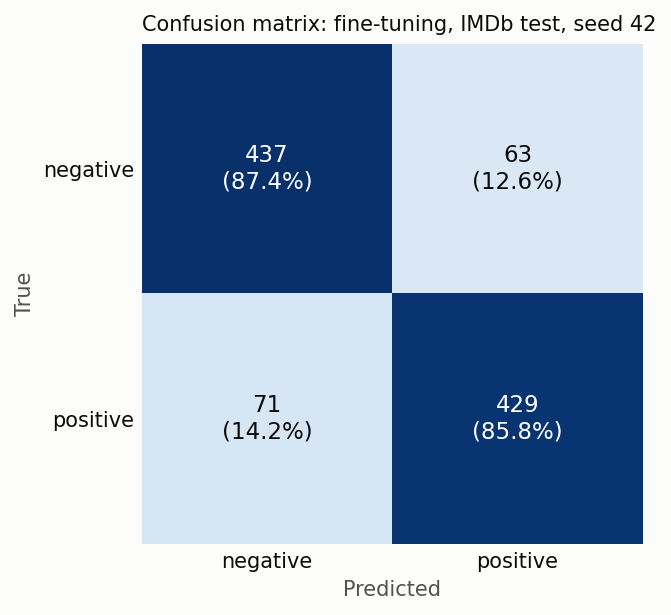

In [13]:
def load_preds(name):
    p = pd.read_json(RUNS_DIR / f"{name}.jsonl", lines=True)
    p["pred"] = (p.p_pos >= 0.5).astype(int)
    p["confidence"] = p.p_pos.where(p.pred == 1, 1 - p.p_pos)
    p["correct"] = p.pred == p.label
    return p

preds = load_preds("finetune_f1_T128_s42_imdb")
print(df[(df.run == "finetune_f1_T128_s42") & (df.test_domain == "imdb")][METRICS].T)
cm = confusion_matrix(preds.label, preds.pred)
print(cm)

fig, ax = plt.subplots(figsize=(4.8, 4.2), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.imshow(cm, cmap="Blues", vmin=0)
names = ["negative", "positive"]
ax.set_xticks([0, 1], names); ax.set_yticks([0, 1], names)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=11)
ax.set_xlabel("Predicted", color=MUTED); ax.set_ylabel("True", color=MUTED)
ax.tick_params(length=0, colors=INK)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Confusion matrix: fine-tuning, IMDb test, seed 42", loc="left", color=INK, fontsize=10)
fig.tight_layout()
fig.savefig("confusion_matrix.png")
plt.show()

### Mục 21: confidence analysis

Ngưỡng cho bài toán 2 lớp: Low là 0.5 đến dưới 0.7, Medium là 0.7 đến dưới 0.9, High là từ 0.9 trở lên.

          n  correct  accuracy  mean_confidence  wrong
bin                                                   
Low     115       74    0.6435           0.6037     41
Medium  227      164    0.7225           0.8163     63
High    658      628    0.9544           0.9651     30


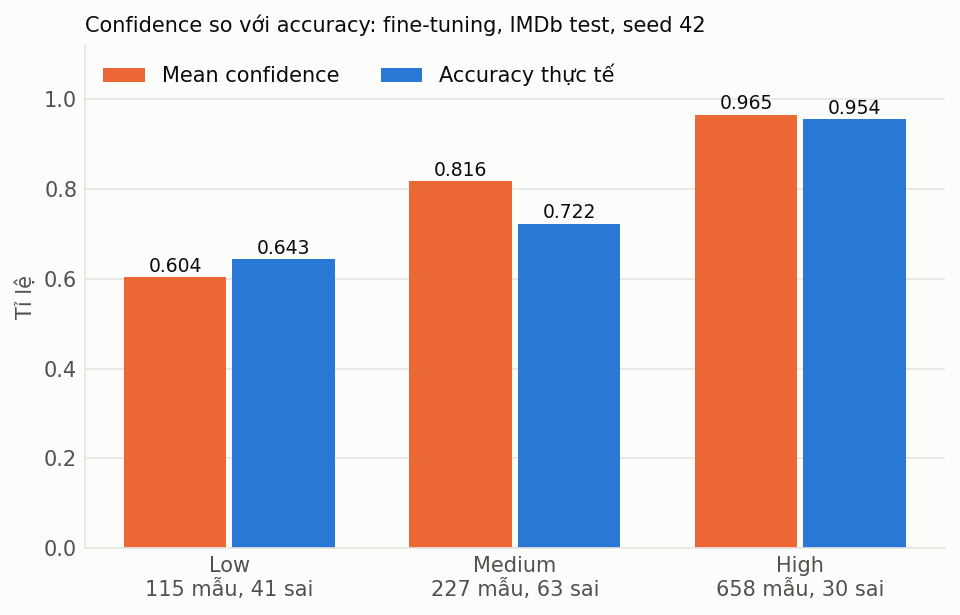

In [14]:
BINS = [0.5, 0.7, 0.9, 1.0001]
NAMES = ["Low", "Medium", "High"]
preds["bin"] = pd.cut(preds.confidence, BINS, labels=NAMES, right=False)
conf = preds.groupby("bin", observed=False).agg(n=("correct", "size"), correct=("correct", "sum"), accuracy=("correct", "mean"), mean_confidence=("confidence", "mean"))
conf["wrong"] = conf.n - conf.correct
print(conf.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4.2), dpi=150)
x = np.arange(3)
ax.bar(x - 0.19, conf.mean_confidence, 0.36, color=COLORS["scratch"], label="Mean confidence")
ax.bar(x + 0.19, conf.accuracy, 0.36, color=COLORS["finetune"], label="Accuracy thực tế")
for i in x:
    ax.text(i - 0.19, conf.mean_confidence.iloc[i] + 0.012, f"{conf.mean_confidence.iloc[i]:.3f}", ha="center", color=INK, fontsize=9)
    ax.text(i + 0.19, conf.accuracy.iloc[i] + 0.012, f"{conf.accuracy.iloc[i]:.3f}", ha="center", color=INK, fontsize=9)
style(fig, ax)
ax.set_xticks(x, [f"{n}\n{conf.n.iloc[i]} mẫu, {conf.wrong.iloc[i]} sai" for i, n in enumerate(NAMES)])
ax.set_ylim(0, 1.12)
ax.set_ylabel("Tỉ lệ", color=MUTED)
ax.set_title("Confidence so với accuracy: fine-tuning, IMDb test, seed 42", loc="left", color=INK, fontsize=10)
ax.legend(frameon=False, loc="upper left", ncol=2, labelcolor=INK)
fig.tight_layout()
fig.savefig("confidence_analysis.png")
plt.show()

### Mục 20: dữ liệu cho error analysis

In [15]:
def show(frame, n):
    for _, r in frame.head(n).iterrows():
        print(f"[true={r.label} pred={r.pred} conf={r.confidence:.3f}, {len(r.text.split())} words]\n{r.text[:700]}\n")

wrong = preds[~preds.correct].sort_values("confidence", ascending=False)
print("False positives:", (wrong.label == 0).sum(), "| False negatives:", (wrong.label == 1).sum())
print("=== FALSE POSITIVES, confidence cao nhất ===")
show(wrong[wrong.label == 0], 6)
print("=== FALSE NEGATIVES, confidence cao nhất ===")
show(wrong[wrong.label == 1], 6)

False positives: 63 | False negatives: 71
=== FALSE POSITIVES, confidence cao nhất ===
[true=0 pred=1 conf=0.983, 65 words]
This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm.

[true=0 pred=1 conf=0.973, 391 words]
Summary: Not worth the film  As an avid Gone With the Wind fan, I was disappointed to watch the original movie and see that they had left out many important characters. Luckily, the film on its own was a wonderful piece. When the book Scarlett came out, I read it in hopes of following two of my favorite literary characters farther on their journey together. While the book lacks any true quality, it remains a good story, and, as long as I was able to separate it from the original, 

In [16]:
# Effect of review length on the error rate, and behaviour on Amazon
preds["words"] = preds.text.str.split().str.len()
preds["length_group"] = pd.cut(preds.words, [0, 100, 200, 400, 10000], labels=["<=100", "101-200", "201-400", ">400"])
print(preds.groupby("length_group", observed=False).correct.agg(["size", "mean"]).round(3))

amazon = load_preds("finetune_f1_T128_s42_amazon")
print(pd.crosstab(amazon.label, amazon.pred))
amazon["bin"] = pd.cut(amazon.confidence, BINS, labels=NAMES, right=False)
print(amazon.groupby("bin", observed=False).correct.agg(["size", "mean"]).round(3))

              size   mean
length_group             
<=100          117  0.915
101-200        491  0.902
201-400        270  0.844
>400           122  0.721
pred     0    1
label          
0      454   46
1       70  430
        size   mean
bin                
Low      116  0.534
Medium   253  0.838
High     631  0.967
